In [199]:
import pandas as pd
import matplotlib.pyplot as plt

reading_base_path = "D://Data//ML//rais_anonymized//rais_anonymized//"
fitbit_sema_hourly_name = "csv_rais_anonymized//hourly_fitbit_sema_df_unprocessed.csv"
fitbit_sema_daily_name = "csv_rais_anonymized//daily_fitbit_sema_df_unprocessed.csv"
df_hourly = pd.read_csv(reading_base_path+fitbit_sema_hourly_name)
df_daily = pd.read_csv(reading_base_path+fitbit_sema_daily_name)
print(df_daily.columns,len(df_daily.columns))
print(df_daily["HAPPY"].unique())
known_variable_list = ['lightly_active_minutes', 'moderately_active_minutes', 'very_active_minutes',
          'sleep_duration', 'minutesAsleep', 'calories']
mood_list = ['ALERT', 'HAPPY', 'NEUTRAL', 'RESTED/RELAXED', 'SAD', 'TENSE/ANXIOUS',
       'TIRED', 'ENTERTAINMENT']

Index(['Unnamed: 0', 'id', 'date', 'nightly_temperature', 'nremhr', 'rmssd',
       'spo2', 'full_sleep_breathing_rate', 'stress_score',
       'sleep_points_percentage', 'exertion_points_percentage',
       'responsiveness_points_percentage', 'daily_temperature_variation',
       'badgeType', 'calories', 'filteredDemographicVO2Max', 'distance',
       'activityType', 'bpm', 'lightly_active_minutes',
       'moderately_active_minutes', 'very_active_minutes', 'sedentary_minutes',
       'mindfulness_session', 'scl_avg', 'resting_hr', 'sleep_duration',
       'minutesToFallAsleep', 'minutesAsleep', 'minutesAwake',
       'minutesAfterWakeup', 'sleep_efficiency', 'sleep_deep_ratio',
       'sleep_wake_ratio', 'sleep_light_ratio', 'sleep_rem_ratio', 'steps',
       'minutes_in_default_zone_1', 'minutes_below_default_zone_1',
       'minutes_in_default_zone_2', 'minutes_in_default_zone_3', 'age',
       'gender', 'bmi', 'step_goal', 'min_goal', 'max_goal', 'step_goal_label',
       'ALERT',

C:\Users\24230\AppData\Local\Temp\ipykernel_10248\1722896782.py:7: DtypeWarning: Columns (0: badgeType, 1: mindfulness_session, 2: bmi, 3: step_goal) have mixed types. Specify dtype option on import or set low_memory=False.
  df_hourly = pd.read_csv(reading_base_path+fitbit_sema_hourly_name)


Tried to read two files:
csv_rais_anonymized//hourly_fitbit_sema_df_unprocessed.csv
csv_rais_anonymized//daily_fitbit_sema_df_unprocessed.csv
I guess the bson files are huge because some data was recorded at high frequency but in the intial stage, we don't neccessarily need them. So I just stick to these two files. 
Some features of the data:
1. sleep relevant data appears only in daily data 
2. exercise data appears in both dataset. Daily data is the sum of the hourly data per day. 
3. Mood data is a little wired: in hourly dataset, it did appears roughly 3 times per day while in daily dataset it only appears once. And the value maximum in both data set it capped at 1. So My initial idea is using the hourly data and counting the times of each mood happenning. For example, if HAPPY happens 3 times, the HAPPY column value will appear as 3. 
    a. There are a lot of rows which all moods are 0, which required to be dropped
    b. Similarly, the NA rows of MOOD need to be dropped too.
4. Some physical data like spo2, heart rate etc, even they are good, but the data points are much less than mood data somehow, so I dropped them at this stage.


In [200]:

print(df_daily[known_variable_list].describe())

       lightly_active_minutes  moderately_active_minutes  very_active_minutes  \
count             7083.000000                7083.000000          7083.000000   
mean               131.825921                  14.143724            14.509389   
std                121.081398                  23.840320            27.489127   
min                  0.000000                   0.000000             0.000000   
25%                  0.000000                   0.000000             0.000000   
50%                133.000000                   0.000000             0.000000   
75%                225.000000                  21.000000            19.000000   
max                585.000000                 289.000000           409.000000   

       sleep_duration  minutesAsleep     calories  
count    3.551000e+03    3551.000000  6660.000000  
mean     2.700032e+07     393.071529  2182.955429  
std      6.774092e+06      98.382524   704.189313  
min      3.600000e+06       0.000000     0.690000  
25%      2

Show that the mood value are capped at 1 in both daily and hourly data

In [201]:

print(df_daily[mood_list].describe())

             ALERT        HAPPY      NEUTRAL  RESTED/RELAXED          SAD  \
count  2290.000000  2290.000000  2290.000000     2290.000000  2290.000000   
mean      0.133188     0.273799     0.262882        0.389083     0.055459   
std       0.339852     0.446005     0.440295        0.487649     0.228923   
min       0.000000     0.000000     0.000000        0.000000     0.000000   
25%       0.000000     0.000000     0.000000        0.000000     0.000000   
50%       0.000000     0.000000     0.000000        0.000000     0.000000   
75%       0.000000     1.000000     1.000000        1.000000     0.000000   
max       1.000000     1.000000     1.000000        1.000000     1.000000   

       TENSE/ANXIOUS        TIRED  ENTERTAINMENT  
count    2290.000000  2290.000000    2290.000000  
mean        0.220087     0.384279       0.084716  
std         0.414396     0.486531       0.278520  
min         0.000000     0.000000       0.000000  
25%         0.000000     0.000000       0.000000  


In [202]:
print(df_hourly[mood_list].describe())

             ALERT        HAPPY      NEUTRAL  RESTED/RELAXED          SAD  \
count  5029.000000  5029.000000  5029.000000     5029.000000  5029.000000   
mean      0.068403     0.157089     0.163452        0.234241     0.029628   
std       0.252462     0.363921     0.369814        0.423566     0.169576   
min       0.000000     0.000000     0.000000        0.000000     0.000000   
25%       0.000000     0.000000     0.000000        0.000000     0.000000   
50%       0.000000     0.000000     0.000000        0.000000     0.000000   
75%       0.000000     0.000000     0.000000        0.000000     0.000000   
max       1.000000     1.000000     1.000000        1.000000     1.000000   

       TENSE/ANXIOUS        TIRED  ENTERTAINMENT  
count    5029.000000  5029.000000    5029.000000  
mean        0.123285     0.223901       0.041559  
std         0.328797     0.416898       0.199599  
min         0.000000     0.000000       0.000000  
25%         0.000000     0.000000       0.000000  


An example of a single user's first 40 days data

unique dates: 40 of 40 rows


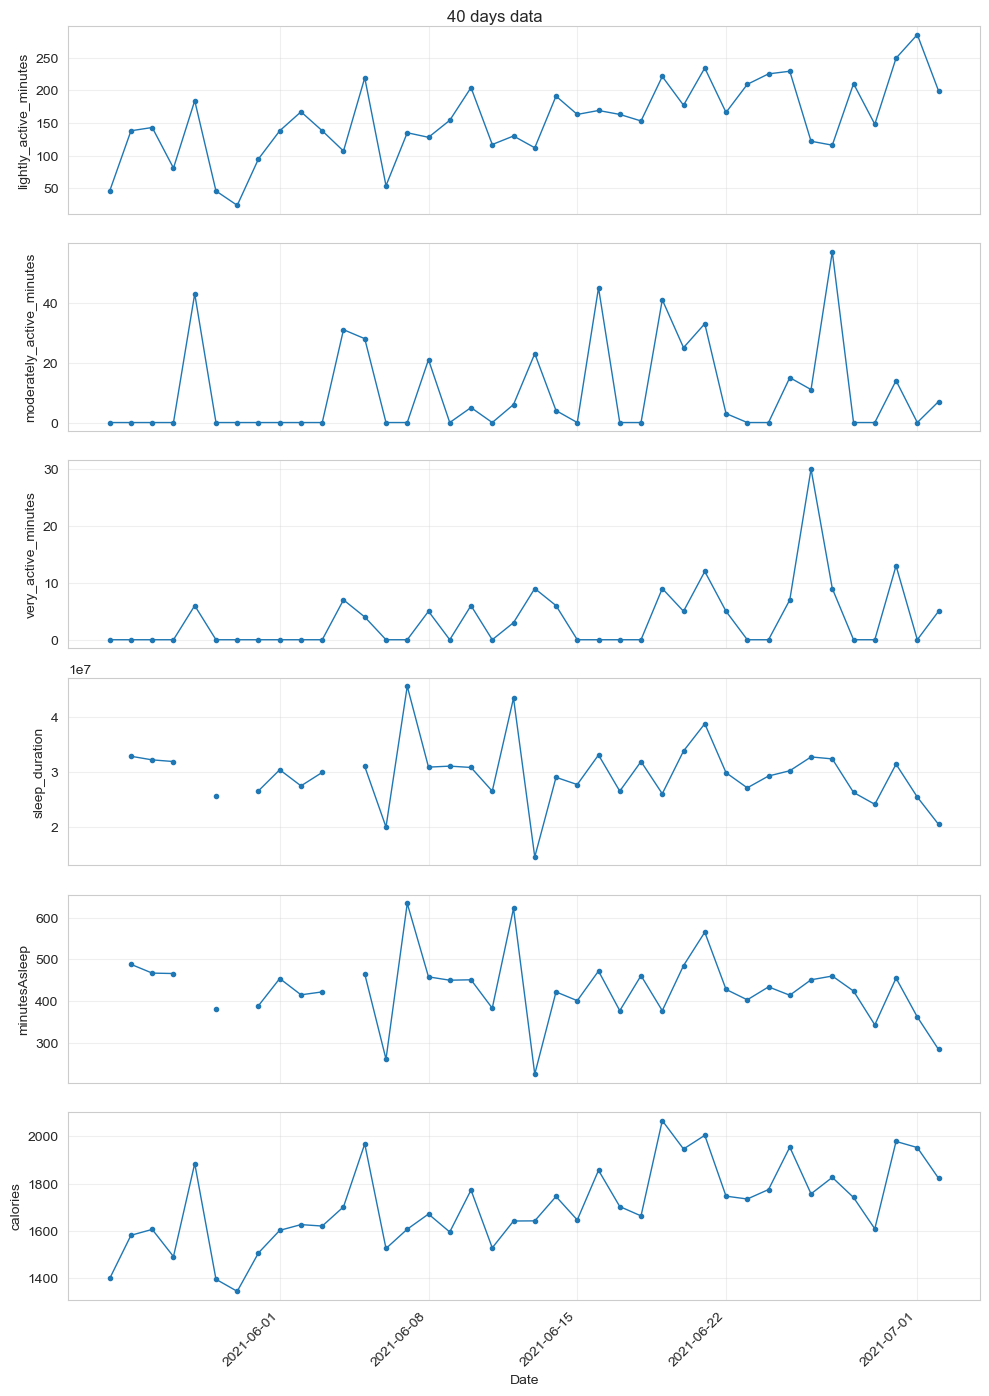

In [209]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


df_test = df_daily[df_daily['id'] == id_list[2]].copy()
d40 = df_test.head(40).reset_index(drop=True)      # first 40 rows, original order
d40["date"] = pd.to_datetime(d40["date"])

def plot_rows(data, cols, title):
    present = [c for c in cols if c in data.columns and data[c].notna().any()]
    skipped = [c for c in cols if c not in present]
    if skipped:
        print(f"{title}: skipped (missing or all NaN): {skipped}")
    if not present:
        return
    fig, axes = plt.subplots(len(present), 1, figsize=(10, 2.2 * len(present) + 1),
                             sharex=True, squeeze=False)
    for ax, col in zip(axes[:, 0], present):
        ax.plot(data["date"], data[col], marker="o", markersize=3, linewidth=1)
        ax.set_ylabel(col)
        ax.grid(alpha=0.3)
    # shared date axis, readable labels
    axes[-1, 0].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
    fig.autofmt_xdate(rotation=45)
    axes[-1, 0].set_xlabel("Date")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

# check whether the dates repeat within these 40 rows
print("unique dates:", d40["date"].nunique(), "of", len(d40), "rows")

plot_rows(d40, known_variable_list,"40 days data")


Check if data has duplicated ["id", "date"] and the result is no duplicated data

In [210]:
import pandas as pd

known_variable_average_list = ['stress_score', 'spo2', 'filteredDemographicVO2Max',
                               'lightly_active_minutes', 'moderately_active_minutes',
                               'very_active_minutes', 'sleep_duration', 'minutesAsleep']
known_variable_sum_list = ['distance', 'steps', 'calories']
all_vars = [c for c in known_variable_average_list + known_variable_sum_list
            if c in df_daily.columns]

key = ["id", "date"]

# 1. Overall: how many rows share the same user + date?
sizes = df_daily.groupby(key).size()
print("Total rows:", len(df_daily))
print("Unique (id, date) pairs:", len(sizes))
print("Pairs with more than 1 row:", (sizes > 1).sum())
print("Rows that are part of a duplicate pair:", df_daily.duplicated(subset=key, keep=False).sum())
print("\nHow many pairs have 1, 2, 3... rows:")
print(sizes.value_counts().sort_index())

# 2. Per variable: among duplicated (id, date) pairs, how many have
#    - more than one non-missing value
#    - more than one DISTINCT value (i.e., the duplicates disagree)
dup = df_daily[df_daily.duplicated(subset=key, keep=False)]
g = dup.groupby(key)

summary = pd.DataFrame({
    "pairs_with_multiple_values": {v: (g[v].count() > 1).sum() for v in all_vars},
    "pairs_with_conflicting_values": {v: (g[v].nunique() > 1).sum() for v in all_vars},
})
print("\nDuplicated pairs per variable:")
print(summary)

Total rows: 7410
Unique (id, date) pairs: 7410
Pairs with more than 1 row: 0
Rows that are part of a duplicate pair: 0

How many pairs have 1, 2, 3... rows:
1    7410
Name: count, dtype: int64

Duplicated pairs per variable:
                           pairs_with_multiple_values  \
stress_score                                        0   
spo2                                                0   
filteredDemographicVO2Max                           0   
lightly_active_minutes                              0   
moderately_active_minutes                           0   
very_active_minutes                                 0   
sleep_duration                                      0   
minutesAsleep                                       0   
distance                                            0   
steps                                               0   
calories                                            0   

                           pairs_with_conflicting_values  
stress_score                   

This process the mood data from hourly. It adds the mood counts per day. 
There seems some data has more than 3 counts, which need to be removed later

In [179]:
# reobtain the mood from the data
# sleep and exercise data
SE_id_list = ["id","date"]+known_variable_average_list+known_variable_sum_list
df_daily_SE = df_daily[SE_id_list]

# mood data from hourly
mood_id_list = ["id", "date"]+mood_list
df_daily_MOOD = (df_hourly
                 .groupby(["id", "date"], as_index=False)[mood_list]
                 .sum())
df_daily_MOOD = df_daily_MOOD[df_daily_MOOD[mood_list].sum(axis=1) > 0]
df_daily_MOOD.describe()
# df_daily_MOOD.head(20)
# a lot of all 0
# check the 3 times test per day -- seems not necessarily morning, noon and evening. 
# df_hourly[df_hourly["date"]=="2021-05-27"][["hour"]+mood_id_list].dropna().head(20)



,ALERT,HAPPY,NEUTRAL,RESTED/RELAXED,SAD,TENSE/ANXIOUS,TIRED,ENTERTAINMENT
count,2290.000000,2290.000000,2290.000000,2290.000000,2290.000000,2290.000000,2290.000000,2290.000000
mean,0.150218,0.344978,0.358952,0.514410,0.065066,0.270742,0.491703,0.091266
std,0.403309,0.622663,0.676298,0.730663,0.289095,0.556992,0.703962,0.311373
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
max,3.000000,3.000000,4.000000,4.000000,3.000000,3.000000,3.000000,3.000000


While the daily data only has one count per mood at maximum...

In [180]:
df_daily[mood_list].describe()

,ALERT,HAPPY,NEUTRAL,RESTED/RELAXED,SAD,TENSE/ANXIOUS,TIRED,ENTERTAINMENT
count,2290.000000,2290.000000,2290.000000,2290.000000,2290.000000,2290.000000,2290.000000,2290.000000
mean,0.133188,0.273799,0.262882,0.389083,0.055459,0.220087,0.384279,0.084716
std,0.339852,0.446005,0.440295,0.487649,0.228923,0.414396,0.486531,0.278520
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


Merge sleep/exercise from daily dataframe with mood counts from hourly dataframe
Now all variables have same dimensions.

In [211]:
# merge two df 
df_daily_merged = df_daily_SE.merge(
    df_daily_MOOD,
    on=["id", "date"],
    how="inner",            # keep all daily SE rows
    validate="one_to_one"  # raises an error if either side has duplicate (id, date) pairs
)
df_daily_merged.describe()
# analysis data with enough samples
# print(df_daily_merged.columns)
sample_list = ['id', 'date',
       'lightly_active_minutes', 'moderately_active_minutes',
       'very_active_minutes', 'sleep_duration', 'minutesAsleep', 'calories', 'ALERT', 'HAPPY', 'NEUTRAL', 'RESTED/RELAXED',
       'SAD', 'TENSE/ANXIOUS', 'TIRED', 'ENTERTAINMENT']
df_sample = df_daily_merged[sample_list]
df_sample = df_sample.dropna()
df_sample.dropna().describe()

,lightly_active_minutes,moderately_active_minutes,very_active_minutes,sleep_duration,minutesAsleep,calories,ALERT,HAPPY,NEUTRAL,RESTED/RELAXED,SAD,TENSE/ANXIOUS,TIRED,ENTERTAINMENT
count,1766.000000,1766.000000,1766.000000,1.766000e+03,1766.000000,1766.000000,1766.000000,1766.000000,1766.000000,1766.000000,1766.000000,1766.000000,1766.000000,1766.000000
mean,219.193092,24.716308,24.030578,2.712109e+07,395.023216,2517.242101,0.165912,0.345413,0.386750,0.519819,0.067384,0.273499,0.520951,0.092865
std,92.833407,29.651315,34.085564,6.763020e+06,98.414876,701.696481,0.423387,0.626740,0.701617,0.733962,0.294406,0.561715,0.722258,0.312869
min,0.000000,0.000000,0.000000,3.600000e+06,52.000000,996.970000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,153.000000,0.000000,0.000000,2.352000e+07,343.000000,2004.017500,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,217.000000,16.000000,12.000000,2.754000e+07,401.500000,2414.785000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,280.000000,36.000000,35.000000,3.118500e+07,453.750000,2940.787500,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
max,585.000000,289.000000,409.000000,7.446000e+07,1094.000000,8050.870000,3.000000,3.000000,4.000000,4.000000,3.000000,3.000000,3.000000,3.000000


Add new column: next day's mood so that the correlation between next day mood and current day exercise/sleep can be compared
and dropped na rows

In [212]:
# add new date column 
# date to predict
next_cols = [f"{m}_next" for m in mood_list]
print("next-col",next_cols)

# next-day moods, keyed to the previous day (only id, date and the *_next columns)
mood_next = df_sample[["id", "date"] + mood_list].copy()
mood_next["date"] = pd.to_datetime(mood_next["date"]) - pd.Timedelta(days=1)
mood_next = mood_next.rename(columns=dict(zip(mood_list, next_cols)))

df_sample["date"] = pd.to_datetime(df_sample["date"])

# add only the new *_next columns to df_sample
df_next = df_sample.merge(mood_next, on=["id", "date"], how="left", validate="one_to_one")

# drop rows with no next-day mood
df_next = df_next.dropna(subset=next_cols).reset_index(drop=True)

print(len(df_sample), "->", len(df_next))
print(df_next.columns.tolist())


next-col ['ALERT_next', 'HAPPY_next', 'NEUTRAL_next', 'RESTED/RELAXED_next', 'SAD_next', 'TENSE/ANXIOUS_next', 'TIRED_next', 'ENTERTAINMENT_next']
1766 -> 1462
['id', 'date', 'lightly_active_minutes', 'moderately_active_minutes', 'very_active_minutes', 'sleep_duration', 'minutesAsleep', 'calories', 'ALERT', 'HAPPY', 'NEUTRAL', 'RESTED/RELAXED', 'SAD', 'TENSE/ANXIOUS', 'TIRED', 'ENTERTAINMENT', 'ALERT_next', 'HAPPY_next', 'NEUTRAL_next', 'RESTED/RELAXED_next', 'SAD_next', 'TENSE/ANXIOUS_next', 'TIRED_next', 'ENTERTAINMENT_next']


Try to perform EDA to see the correlation between sleep/exercise and mood

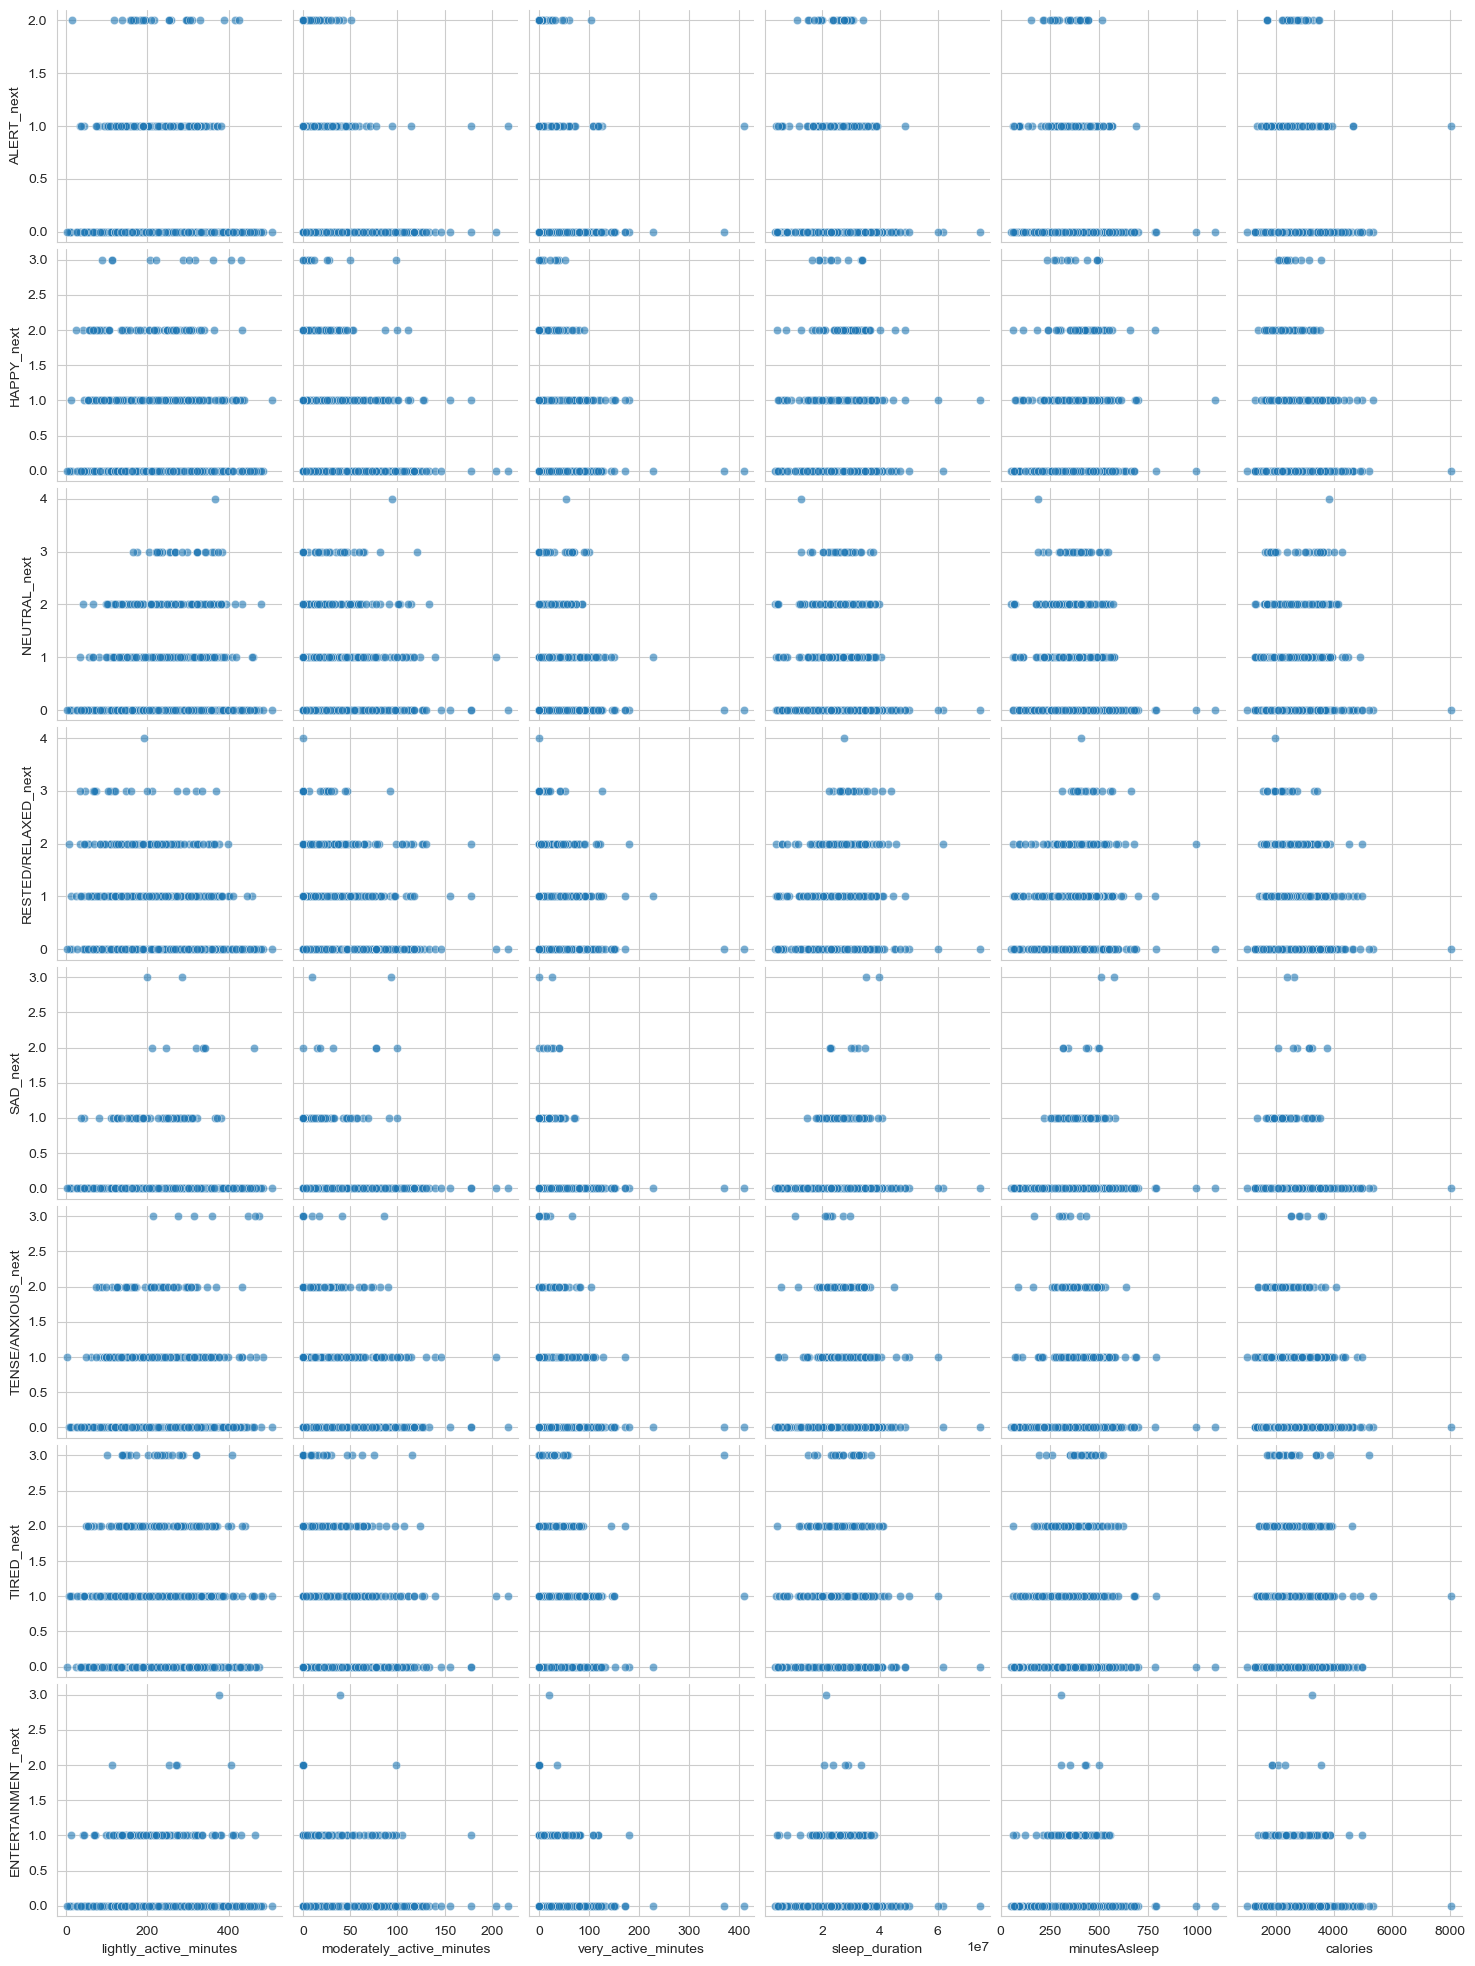

In [213]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.neighbors import KNeighborsRegressor
from sklearn.dummy import DummyRegressor

## import root_mean_squared_error
from sklearn.metrics import root_mean_squared_error
import seaborn as sns

sns.set_style("whitegrid")

df_train, df_test = train_test_split(
    df_next, test_size=0.2, random_state=216, shuffle=True
)

sns.pairplot(data =df_train,
                x_vars = ['lightly_active_minutes', 'moderately_active_minutes',
                       'very_active_minutes', 'sleep_duration', 'minutesAsleep', 'calories'],
                y_vars = next_cols,
                plot_kws = {'alpha':.6})

plt.show()

There were no obvious correlation: so I tried to split mood to good and bad mood to see if it visualizes better. But still no :(

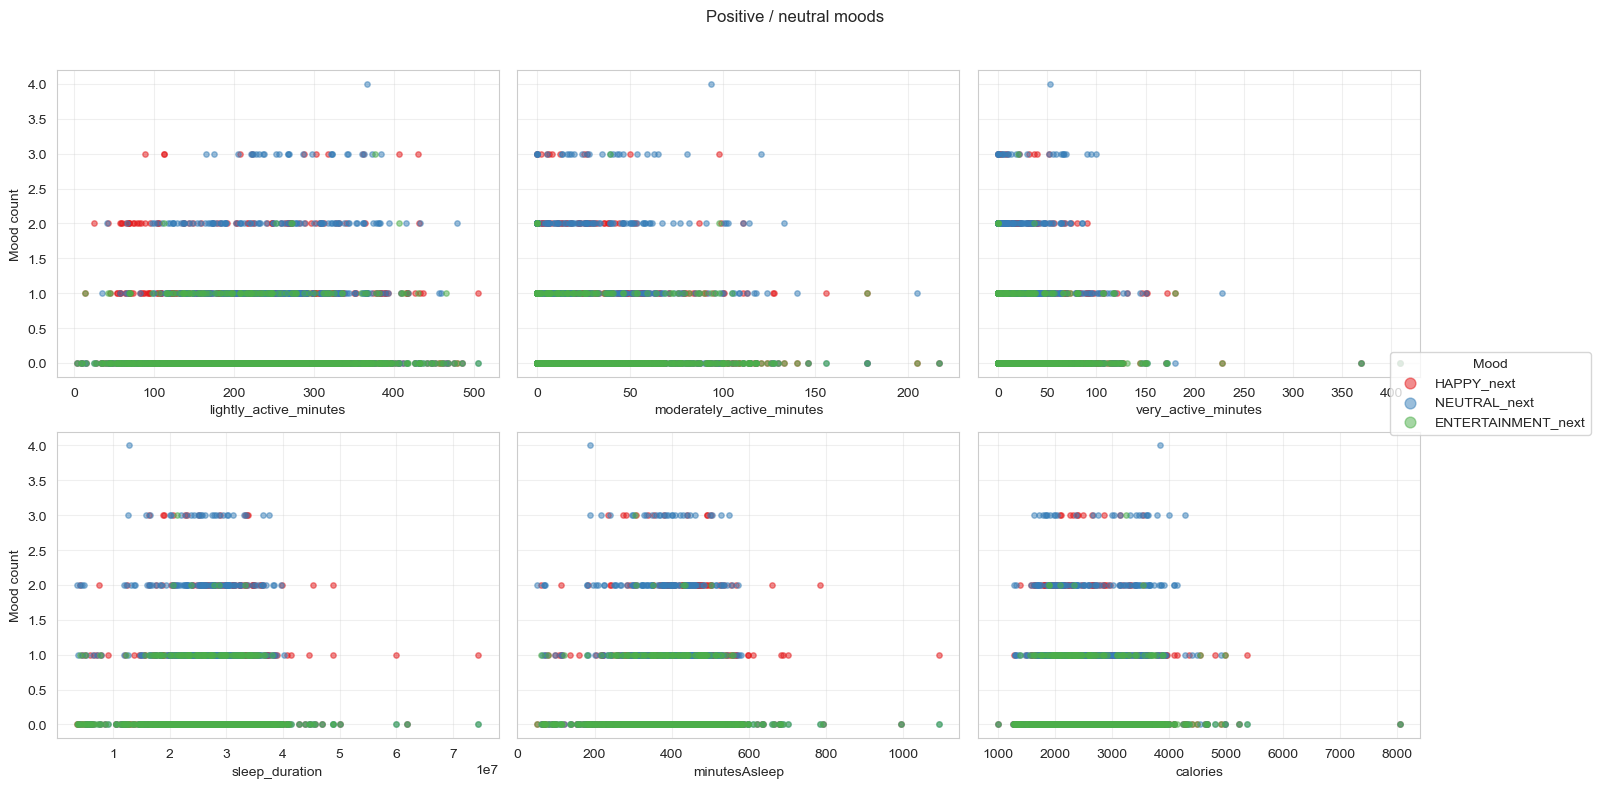

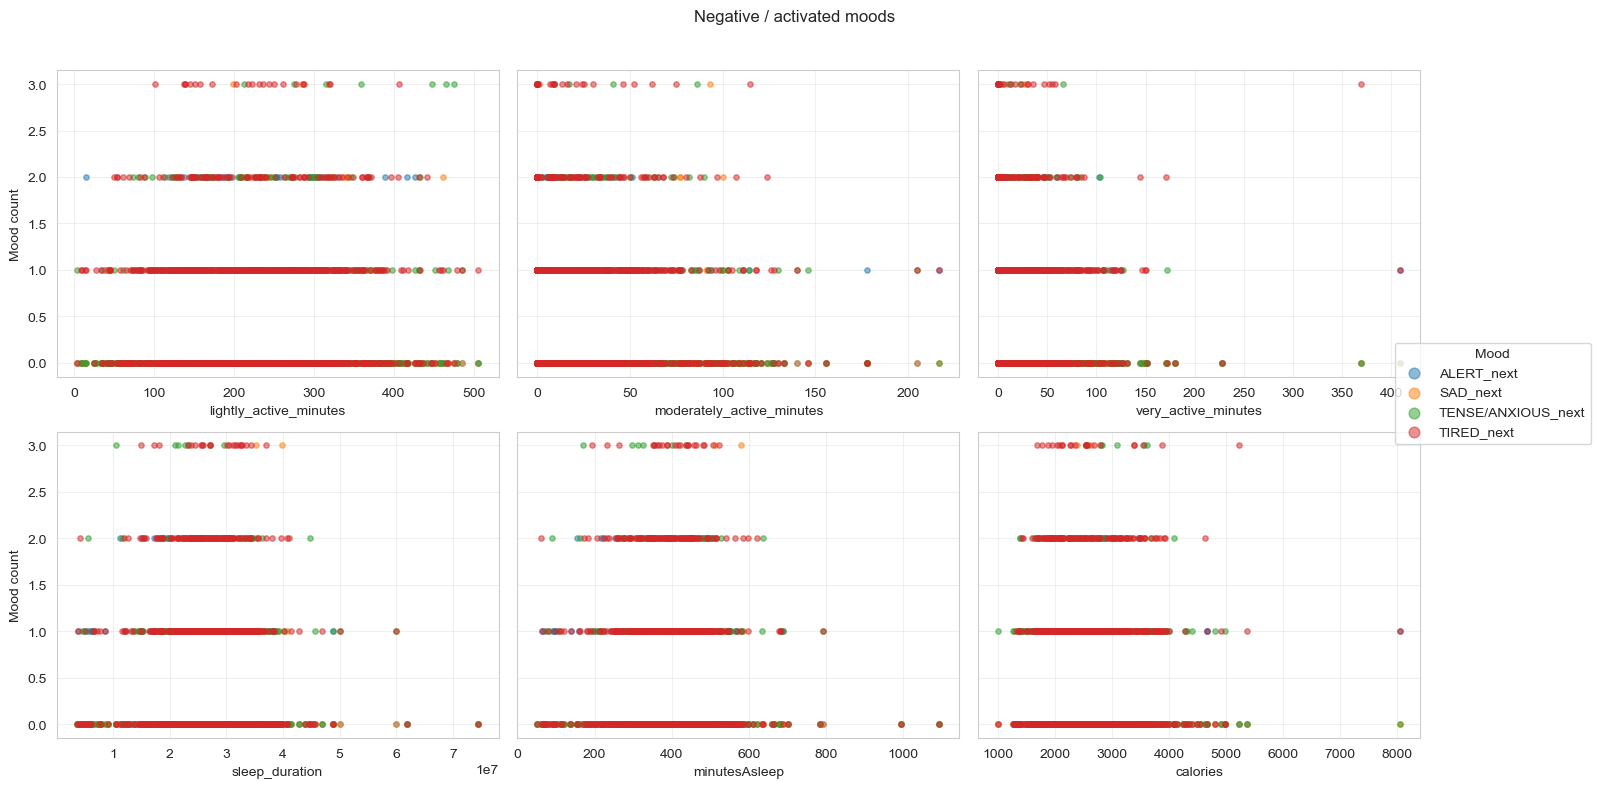

In [214]:
import matplotlib.pyplot as plt
import seaborn as sns

x_vars = ['lightly_active_minutes', 'moderately_active_minutes', 'very_active_minutes',
          'sleep_duration', 'minutesAsleep', 'calories']
# y_good_vars = [ 'HAPPY', 'NEUTRAL', 'ENTERTAINMENT']
# y_bad_vars = ['ALERT','SAD', 'TENSE/ANXIOUS', 'TIRED']

y_good_vars = [ 'HAPPY_next', 'NEUTRAL_next', 'ENTERTAINMENT_next']
y_bad_vars = ['ALERT_next','SAD_next', 'TENSE/ANXIOUS_next', 'TIRED_next']

def plot_moods(data, x_vars, y_vars, title, palette_name="tab10"):
    palette = dict(zip(y_vars, sns.color_palette(palette_name, len(y_vars))))

    fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)
    for ax, x in zip(axes.ravel(), x_vars):
        for y in y_vars:
            ax.scatter(data[x], data[y], s=15, alpha=0.5, color=palette[y], label=y)
        ax.set_xlabel(x)
        ax.grid(alpha=0.3)

    axes[0, 0].set_ylabel("Mood count")
    axes[1, 0].set_ylabel("Mood count")

    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="center right", title="Mood", markerscale=2)
    fig.suptitle(title)
    fig.tight_layout(rect=[0, 0, 0.9, 0.96])
    plt.show()

plot_moods(df_train, x_vars, y_good_vars, "Positive / neutral moods", palette_name="Set1")
plot_moods(df_train, x_vars, y_bad_vars,  "Negative / activated moods", palette_name="tab10")

But I stilled tried to apply the regresion to see the results:
But it seems that regression doesn't look good

In [218]:
import numpy as np
mood_train = df_train
## Make a KFold object
## remember to set a random_state and set shuffle = True
num_splits = 5
num_models = 4
kfold = KFold(num_splits, random_state=216, shuffle=True)

## This array will hold the mse for each model and split

known_columns = ['lightly_active_minutes', 'moderately_active_minutes',
                       'very_active_minutes', 'sleep_duration', 'minutesAsleep', 'calories']


## loop through the kfold here
for column in next_cols:
    rmses = np.zeros((num_models, num_splits))

    ## sets a split counter
    i = 0
    predicted_columns = [column]
    print("evaluation", column)
    for train_index, test_index in kfold.split(mood_train):
        ## cv training set
        mood_tt = mood_train.iloc[train_index]

        ## cv holdout set
        mood_ho = mood_train.iloc[test_index]

        ## Fit and get ho mse for the baseline model
        mean_regressor = DummyRegressor(strategy="mean")
        mean_regressor.fit(mood_tt[known_columns], mood_tt[predicted_columns])
        baseline_pred = mean_regressor.predict(mood_ho[known_columns])

        rmses[0, i] = root_mean_squared_error(mood_ho[predicted_columns], baseline_pred)

        
        ## Fit and get ho mse for mlr model
        mlr = LinearRegression()

        mlr.fit(mood_tt[known_columns], mood_tt[predicted_columns])

        rmses[2, i] = root_mean_squared_error(
            mood_ho[predicted_columns],
            mlr.predict(mood_ho[known_columns]),
        )

        ## Fit and get ho mse for the spatial model
        knn = KNeighborsRegressor(10)

        knn.fit(mood_tt[known_columns], mood_tt[predicted_columns])

        rmses[3, i] = root_mean_squared_error(
            mood_ho[predicted_columns],
            knn.predict(mood_ho[known_columns]),
        )

        i = i + 1
    print(f"Baseline Avg. CV RMSE: {np.mean(rmses[0,:])} and STD: {np.std(rmses[0,:])}")
    print(f"SLR Avg. CV MSE: {np.mean(rmses[1,:])} and STD: {np.std(rmses[1,:])}")
    print(f"MLR Avg. CV MSE: {np.mean(rmses[2,:])} and STD: {np.std(rmses[2,:])}")
    print(f"neighbour regressor CV MSE: {np.mean(rmses[3,:])} and STD: {np.std(rmses[3,:])}","\n")    


evaluation ALERT_next
Baseline Avg. CV RMSE: 0.43177970732686877 and STD: 0.04218943822754361
SLR Avg. CV MSE: 0.0 and STD: 0.0
MLR Avg. CV MSE: 0.42421435862032836 and STD: 0.04297745745468041
neighbour regressor CV MSE: 0.45671069321313257 and STD: 0.040865089277089865 

evaluation HAPPY_next
Baseline Avg. CV RMSE: 0.6199200471970313 and STD: 0.049522147947563586
SLR Avg. CV MSE: 0.0 and STD: 0.0
MLR Avg. CV MSE: 0.6207277253109219 and STD: 0.04786337674122671
neighbour regressor CV MSE: 0.6556390823826004 and STD: 0.045300187408355966 

evaluation NEUTRAL_next
Baseline Avg. CV RMSE: 0.7404775062304157 and STD: 0.03957334458101603
SLR Avg. CV MSE: 0.0 and STD: 0.0
MLR Avg. CV MSE: 0.7322081474953042 and STD: 0.03721864057827415
neighbour regressor CV MSE: 0.7748050453696298 and STD: 0.03907356734789853 

evaluation RESTED/RELAXED_next
Baseline Avg. CV RMSE: 0.7575181562890484 and STD: 0.04833242499708959
SLR Avg. CV MSE: 0.0 and STD: 0.0
MLR Avg. CV MSE: 0.7528169231733212 and STD: 0

The resutls shows the all models: dummy model, multi linear regression or neighbour regression all did bad on the prediction. The RMSE is 0.636 while previous mean is ~ 0.34

In [11]:
location = ['ENTERTAINMENT','GYM', 'HOME', 'HOME_OFFICE', 'OTHER', 'OUTDOORS', 'TRANSIT',
       'WORK/SCHOOL']
mood = ['ALERT', 'HAPPY', 'NEUTRAL',
       'RESTED/RELAXED', 'SAD', 'TENSE/ANXIOUS', 'TIRED']
exercise = ['']
print(df_hourly['activityType'].unique())

# print(df_hourly[location].dropna())
print(df_hourly[df_hourly['ENTERTAINMENT']==1])

<ArrowStringArray>
[                                                           nan,
                                                     '['Walk']',
                                             '['Walk', 'Walk']',
                                                    '['Sport']',
                                          '['Aerobic Workout']',
                                             '['Yoga/Pilates']',
                                            '['Sport', 'Walk']',
                                           '['Sport', 'Sport']',
                                            '['Walk', 'Sport']',
                                                     '['Swim']',
                                  '['Aerobic Workout', 'Walk']',
                       '['Aerobic Workout', 'Aerobic Workout']',
                                  '['Walk', 'Aerobic Workout']',
                                                     '['Bike']',
                                       '['Bike', 'Elliptical']',
      

In [ ]:
df_hourly_mood = df_hourly